<a href="https://colab.research.google.com/github/BintangPancahaya/PemMes_2026/blob/main/JS07/JS07_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 - Tugas Lab: Klasterisasi Data Nasabah Kartu Kredit

### Persiapan - Import Library dan Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


### Soal 1 - Scatterplot `Avg_Credit_Limit` vs `Total_Credit_Cards`

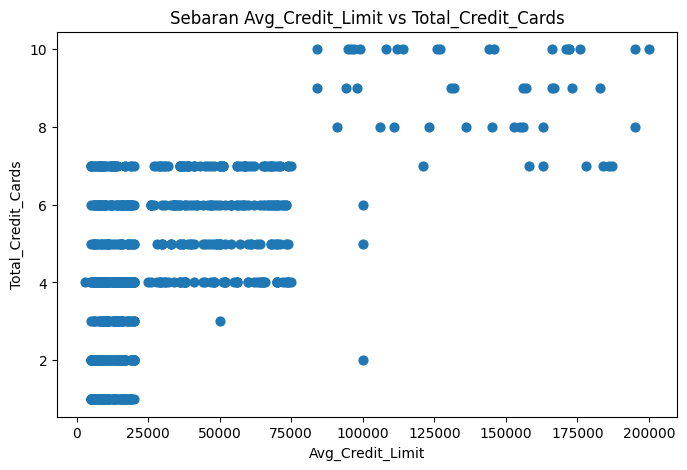

Korelasi Pearson: 0.6088604935524963


In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=40)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

print('Korelasi Pearson:', df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards']))

**Jawaban Soal 1:**

Sebaran data **tidak dapat dikatakan linier**. Memang ada kecenderungan positif (korelasi ±0,61: semakin banyak kartu kredit, limit cenderung lebih tinggi), tetapi titik-titiknya tidak membentuk satu pola garis lurus. Data justru terkumpul dalam beberapa kelompok:
- nasabah dengan 1–3 kartu dan limit rendah (umumnya < 20.000),
- nasabah dengan 4–7 kartu dan limit menengah (sebagian besar < 75.000),
- nasabah dengan 8–10 kartu dan limit sangat tinggi (± 84.000–200.000) yang terpisah jauh di kanan atas.

Selain itu `Total_Credit_Cards` bernilai diskrit (1–10) sehingga titik tersusun dalam baris-baris horizontal, dan ada lompatan besar limit antara kelompok 7 kartu dan 8 kartu. Pola berkelompok seperti ini lebih cocok dianalisis dengan klasterisasi daripada dianggap hubungan linier.

### Soal 2 - Model K-Means dan Menentukan k Terbaik dengan Elbow Method

In [ ]:
# Fitur untuk K-Means: Avg_Credit_Limit dan Total_Credit_Cards
X2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

# Standardisasi agar skala Avg_Credit_Limit (ribuan) tidak mendominasi Total_Credit_Cards (1-10)
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)

k=1  SSE=1320.00
k=2  SSE=698.29
k=3  SSE=334.72
k=4  SSE=235.39
k=5  SSE=163.47
k=6  SSE=128.96
k=7  SSE=99.37
k=8  SSE=86.53
k=9  SSE=74.53
k=10  SSE=64.83


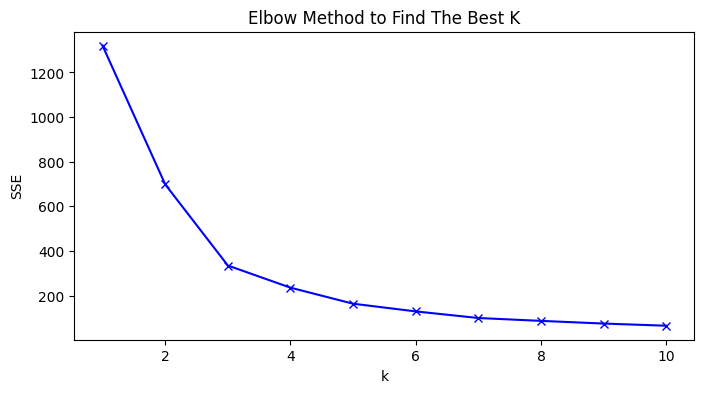

In [ ]:
# Elbow Method
sse = []
K = range(1, 11)

for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X2_scaled)
    sse.append(km.inertia_)

for k, s in zip(K, sse):
    print(f'k={k}  SSE={s:.2f}')

plt.figure(figsize=(8,4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method to Find The Best K')
plt.show()

**Analisis Soal 2:**

Berdasarkan linechart elbow, nilai SSE turun sangat tajam dari k=1 (±1320) ke k=2 (±698) dan k=3 (±335). Setelah k=3, penurunannya mulai landai (k=4 ±235, k=5 ±164, dan seterusnya hanya berkurang sedikit demi sedikit). Titik "siku" (elbow) berada di **k = 3**, sehingga jumlah cluster terbaik yang dipilih adalah **3**.

Pemilihan ini juga sesuai dengan pengamatan visual pada Soal 1 yang memperlihatkan tiga kelompok nasabah (limit rendah – sedikit kartu, limit menengah – kartu sedang, limit tinggi – banyak kartu). Menambah k di atas 3 memang menurunkan SSE, tetapi hanya karena cluster dipecah menjadi lebih kecil, bukan karena muncul kelompok baru yang bermakna.

### Soal 3 - Visualisasi Hasil Klasterisasi K-Means

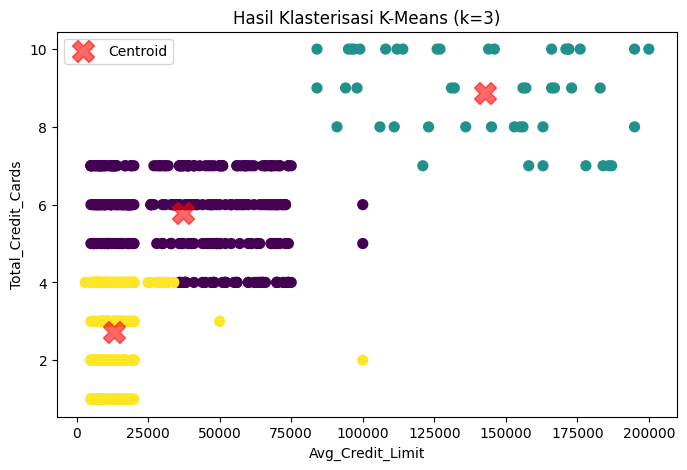

SSE: 334.72447276058625


Avg_Credit_Limit       Total_Credit_Cards      
                           mean count               mean count
Cluster_KMeans                                                
0                  37160.606061   330           5.787879   330
1                 142750.000000    48           8.875000    48
2                  13134.751773   282           2.730496   282

In [ ]:
# Model K-Means dengan k terbaik = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X2_scaled)
df['Cluster_KMeans'] = y_kmeans

# Centroid dikembalikan ke skala asli untuk di-plot
centers = scaler2.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8,5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=y_kmeans, s=50, cmap='viridis')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=250, alpha=0.6, marker='X', label='Centroid')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.legend()
plt.show()

print('SSE:', kmeans.inertia_)
df.groupby('Cluster_KMeans')[['Avg_Credit_Limit', 'Total_Credit_Cards']].agg(['mean', 'count'])

### Soal 4 - Model DBSCAN dengan Seluruh Variabel

In [ ]:
# Seluruh variabel yang dapat digunakan (Sl_No dan Customer Key hanya ID, jadi tidak dipakai)
X_all = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
            'Total_visits_online', 'Total_calls_made']]

# Standardisasi, karena DBSCAN berbasis jarak
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

# DBSCAN dengan parameter awal (default sklearn)
dbscan_awal = DBSCAN(eps=0.5, min_samples=5)
cluster_awal = dbscan_awal.fit_predict(X_all_scaled)

n_cluster_awal = len(set(cluster_awal)) - (1 if -1 in cluster_awal else 0)
print('Jumlah cluster :', n_cluster_awal)
print('Jumlah noise   :', list(cluster_awal).count(-1), f'({np.mean(cluster_awal == -1)*100:.1f}%)')

Jumlah cluster : 24
Jumlah noise   : 205 (31.1%)


Dengan parameter awal (eps=0.5, min_samples=5) DBSCAN menghasilkan terlalu banyak cluster kecil dan noise yang besar, artinya eps terlalu kecil untuk data 5 dimensi ini. Parameter perlu ditentukan dengan elbow method pada Soal 5.

### Soal 5 - Menentukan Parameter Terbaik dengan Elbow Method

DBSCAN tidak memakai jumlah cluster k secara langsung. Pada DBSCAN, elbow method diterapkan pada **k-distance graph**: untuk setiap titik dihitung jarak ke tetangga terdekat ke-k (k = `min_samples`), lalu jaraknya diurutkan. Titik "siku" pada grafik menjadi nilai **eps** terbaik.

Nilai `min_samples` diambil dari aturan praktis `min_samples = 2 × jumlah fitur = 2 × 5 = 10`.

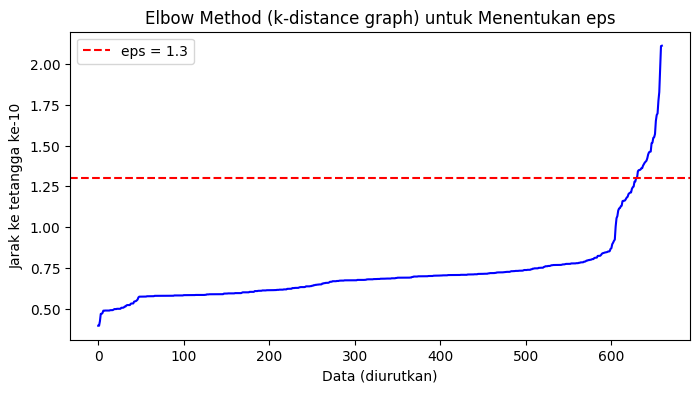

In [ ]:
min_samples = 2 * X_all_scaled.shape[1]   # = 10

neigh = NearestNeighbors(n_neighbors=min_samples)
neigh.fit(X_all_scaled)
distances, _ = neigh.kneighbors(X_all_scaled)

k_distance = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(k_distance, 'b-')
plt.axhline(y=1.3, color='red', linestyle='--', label='eps = 1.3')
plt.xlabel('Data (diurutkan)')
plt.ylabel(f'Jarak ke tetangga ke-{min_samples}')
plt.title('Elbow Method (k-distance graph) untuk Menentukan eps')
plt.legend()
plt.show()

In [ ]:
# Perbandingan beberapa nilai eps di sekitar elbow
for eps in [0.8, 1.0, 1.2, 1.3, 1.4, 1.5]:
    lbl = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_all_scaled)
    n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
    print(f'eps={eps}  cluster={n_cl}  noise={np.mean(lbl == -1)*100:.1f}%')

eps=0.8  cluster=1  noise=8.2%
eps=1.0  cluster=1  noise=8.0%
eps=1.2  cluster=2  noise=2.0%
eps=1.3  cluster=2  noise=1.4%
eps=1.4  cluster=2  noise=0.5%
eps=1.5  cluster=2  noise=0.5%


**Analisis Soal 5:**

Pada k-distance graph, jarak ke tetangga ke-10 naik perlahan untuk sebagian besar data (±0,7–0,9), lalu mulai melengkung tajam di sekitar **1,2–1,4** dan melonjak drastis di ujung kanan (titik-titik yang jarang/outlier). Titik siku tersebut dipilih sebagai **eps = 1.3** dengan **min_samples = 10**.

Dengan eps yang lebih kecil (mis. 0.8) DBSCAN hanya menemukan 1 cluster dengan banyak noise, sedangkan eps = 1.3 sudah stabil menghasilkan **2 cluster** dengan noise kecil (±1,4%). Menaikkan eps lebih jauh hanya mengurangi noise tanpa menambah cluster baru. Jadi untuk DBSCAN dengan seluruh variabel, jumlah cluster terbaik yang terbentuk adalah **2** (+ sebagian kecil noise):
- Cluster 0: mayoritas nasabah (±608 orang) dengan limit rendah–menengah dan kartu sedikit–sedang.
- Cluster 1: ±43 nasabah premium dengan limit sangat tinggi (rata-rata ±146.000), 8–10 kartu, dan sering bertransaksi online.

Jumlah cluster : 2
Jumlah noise   : 9 (1.4%)
Cluster_DBSCAN
 0    608
 1     43
-1      9
Name: count, dtype: int64


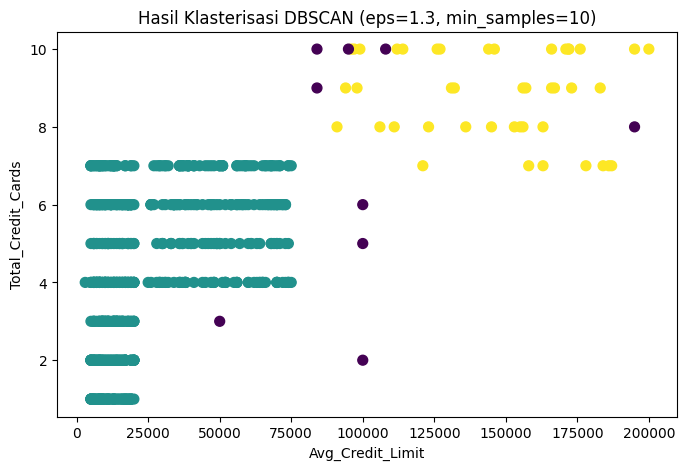

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster_DBSCAN,,,,,
-1,101777.78,7.00,0.33,11.89,2.00
0,25685.86,4.38,2.56,1.91,3.79
1,146186.05,8.81,0.65,10.44,1.05


In [ ]:
# Model DBSCAN final
dbscan = DBSCAN(eps=1.3, min_samples=min_samples)
cluster_db = dbscan.fit_predict(X_all_scaled)
df['Cluster_DBSCAN'] = cluster_db

n_cluster = len(set(cluster_db)) - (1 if -1 in cluster_db else 0)
print('Jumlah cluster :', n_cluster)
print('Jumlah noise   :', list(cluster_db).count(-1), f'({np.mean(cluster_db == -1)*100:.1f}%)')
print(df['Cluster_DBSCAN'].value_counts())

plt.figure(figsize=(8,5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=cluster_db, s=50, cmap='viridis')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi DBSCAN (eps=1.3, min_samples=10)')
plt.show()

df.groupby('Cluster_DBSCAN')[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
                              'Total_visits_online', 'Total_calls_made']].mean().round(2)

### Soal 6 - Silhouette Score dan Davies-Bouldin Index (DBI) Model DBSCAN

In [ ]:
sil = silhouette_score(X_all_scaled, cluster_db)
dbi = davies_bouldin_score(X_all_scaled, cluster_db)

print(f'Silhouette Score    : {sil}')
print(f'Davies-Bouldin Index: {dbi}')

Silhouette Score    : 0.520221036544759
Davies-Bouldin Index: 1.7622997841046224


**Analisis Soal 6:**

- **Silhouette score ±0,52** → cukup baik (rentang -1 s.d. 1, semakin mendekati 1 semakin baik). Artinya sebagian besar nasabah lebih dekat ke anggota cluster-nya sendiri dibanding ke cluster lain.
- **DBI ±1,76** → separasi antar cluster tergolong sedang (semakin kecil semakin baik). Nilainya tidak terlalu rendah karena cluster 0 sangat besar dan menyebar, sementara titik noise (label -1) ikut dihitung sebagai satu kelompok tersendiri.

Secara keseluruhan model DBSCAN berhasil memisahkan kelompok nasabah premium (limit tinggi, banyak kartu, aktif online) dari nasabah reguler, dengan noise yang sangat kecil.